# 04 · K-Nearest Neighbours, Naive Bayes & Support Vector Machines

Three classifiers built on three completely different ideas:

| Algorithm | Core idea | Analogy |
|---|---|---|
| **KNN** | "You are like your neighbours" | asking the 5 people standing closest to you |
| **Naive Bayes** | "Which class makes this data most probable?" | a doctor reasoning from symptoms with probability |
| **SVM** | "Draw the widest possible street between classes" | a road planner keeping maximum distance from houses on both sides |

Each is built 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from collections import Counter
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

def plot_boundary(predict, X, y, ax=None, title="", h=300):
    ax = ax or plt.gca()
    x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, h),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, h))
    Z = np.asarray(predict(np.c_[x0.ravel(), x1.ravel()])).reshape(x0.shape)
    ax.contourf(x0, x1, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=18); ax.set_title(title)

---
# Part A — K-Nearest Neighbours (KNN)

## A1. Intuition
To classify a new point: find the **k** training points closest to it, and take a **majority vote** of their labels. (For regression: average their values.)

That's it. There is no training step — KNN just memorises the data (a "lazy learner"). All the work happens at prediction time.

Two choices matter:
1. **k** — small k = wiggly boundary that follows noise (overfit); large k = smooth boundary that may miss detail (underfit).
2. **Distance** — usually Euclidean: $d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_j (a_j - b_j)^2}$.

In [2]:
# 🐍 Pure Python KNN
def euclidean(a, b):
    return math.sqrt(sum((ai - bi) ** 2 for ai, bi in zip(a, b)))

def knn_predict_one(X_train, y_train, x, k=5):
    dists = sorted((euclidean(x, xi), yi) for xi, yi in zip(X_train, y_train))  # distance to every point
    k_labels = [label for _, label in dists[:k]]                                 # labels of k closest
    return Counter(k_labels).most_common(1)[0][0]                                # majority vote

X_train = [[1, 1], [1, 2], [2, 1], [6, 6], [6, 7], [7, 6]]
y_train = ["red", "red", "red", "blue", "blue", "blue"]
print(knn_predict_one(X_train, y_train, [2, 2], k=3))   # near the reds
print(knn_predict_one(X_train, y_train, [5, 5], k=3))   # near the blues

red
blue


In [3]:
# 🔢 NumPy KNN — compute ALL distances at once with broadcasting
class KNNClassifierNP:
    def __init__(self, k=5):
        self.k = k
    def fit(self, X, y):
        self.X, self.y = np.asarray(X, float), np.asarray(y)
        return self
    def predict(self, X):
        X = np.asarray(X, float)
        # ||a-b||² = ||a||² + ||b||² - 2a·b   → an (n_test × n_train) distance matrix without loops
        d2 = (X ** 2).sum(1)[:, None] + (self.X ** 2).sum(1)[None, :] - 2 * X @ self.X.T
        nearest = np.argsort(d2, axis=1)[:, :self.k]           # indices of k nearest per test row
        votes = self.y[nearest]
        return np.array([np.bincount(v).argmax() for v in votes])

from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier
Xm, ym = make_moons(300, noise=0.3, random_state=0)

ours = KNNClassifierNP(k=5).fit(Xm, ym).predict(Xm)
skl = KNeighborsClassifier(5).fit(Xm, ym).predict(Xm)
py = [knn_predict_one(Xm.tolist(), ym.tolist(), x, 5) for x in Xm.tolist()]
print("NumPy vs sklearn agree on", np.mean(ours == skl) * 100, "% of points")
print("pure Python vs sklearn agree on", np.mean(np.array(py) == skl) * 100, "% of points")

NumPy vs sklearn agree on 100.0 % of points
pure Python vs sklearn agree on 100.0 % of points


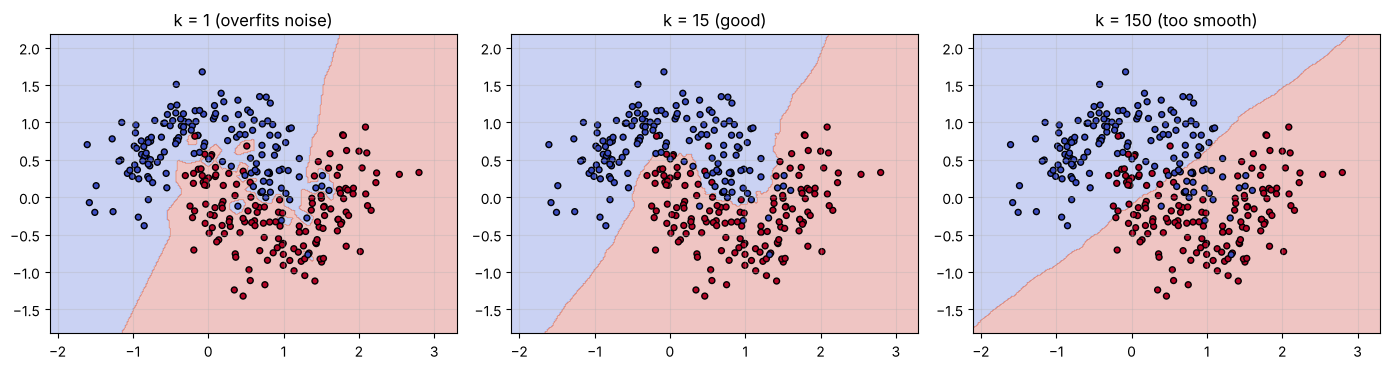

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, k in zip(axes, [1, 15, 150]):
    m = KNNClassifierNP(k).fit(Xm, ym)
    plot_boundary(m.predict, Xm, ym, ax, f"k = {k}" + {1: " (overfits noise)", 15: " (good)", 150: " (too smooth)"}[k])
plt.tight_layout(); plt.show()

## A2. Feature scaling is mandatory for KNN

Distance treats every feature equally *in its raw units*. If one feature is "income in dollars" (0–200,000) and another is "age" (0–100), income completely dominates the distance and age is ignored.

In [5]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xw, yw = load_wine(return_X_y=True)
print("feature ranges:", Xw.min(0).round(1)[:5], "...", Xw.max(0).round(1)[:5])
print(f"KNN raw features:          {cross_val_score(KNeighborsClassifier(5), Xw, yw, cv=5).mean():.3f}")
print(f"KNN standardised features: {cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xw, yw, cv=5).mean():.3f}")

feature ranges: [11.   0.7  1.4 10.6 70. ] ... [ 14.8   5.8   3.2  30.  162. ]
KNN raw features:          0.691
KNN standardised features: 0.949


## A3. The curse of dimensionality

In high dimensions, **everything is far from everything**, and the nearest neighbour is barely nearer than the farthest — so "nearest" stops meaning anything. That's why KNN struggles with hundreds of raw features.

In [6]:
for d in [2, 10, 100, 1000]:
    P = rng.random((500, d))
    dist = np.linalg.norm(P[1:] - P[0], axis=1)
    print(f"d = {d:4d}:  nearest / farthest distance ratio = {dist.min() / dist.max():.3f}")
print("→ ratio approaches 1: all points look equally far away")

d =    2:  nearest / farthest distance ratio = 0.015
d =   10:  nearest / farthest distance ratio = 0.302
d =  100:  nearest / farthest distance ratio = 0.734
d = 1000:  nearest / farthest distance ratio = 0.903
→ ratio approaches 1: all points look equally far away


**KNN summary** — ✅ simple, no training, naturally multi-class, flexible boundaries. ❌ slow predictions on big data (compares against every point — use KD-trees / approximate nearest neighbours), needs scaling, suffers in high dimensions.

---
# Part B — Naive Bayes

## B1. Bayes' rule
$$ P(\text{class} \mid \text{data}) = \frac{P(\text{data} \mid \text{class}) \; P(\text{class})}{P(\text{data})} $$

- **Prior** $P(\text{class})$: how common is the class before seeing any data? (e.g. 30% of email is spam)
- **Likelihood** $P(\text{data} \mid \text{class})$: how typical is this data for that class?
- **Posterior** $P(\text{class} \mid \text{data})$: what we want.

We pick the class with the largest posterior. $P(\text{data})$ is the same for all classes, so we can ignore it.

## B2. The "naive" assumption
With many features $x_1, \dots, x_d$, the likelihood is hard to estimate. Naive Bayes assumes **features are independent given the class**, so it factorises:
$$ P(x_1, \dots, x_d \mid c) = \prod_j P(x_j \mid c) $$

This is almost never exactly true ("free" and "money" co-occur in spam), yet NB often works surprisingly well — it only needs the *ranking* of classes to be right, not the exact probabilities.

**Practical trick:** multiplying many small probabilities underflows to 0, so we add **logs** instead.

## B3. Gaussian Naive Bayes (continuous features)
Assume each feature, within each class, follows a bell curve (normal distribution) with its own mean μ and variance σ²:
$$ P(x_j \mid c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^2}} \exp\left(-\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2}\right) $$
Training = computing a mean and variance per (class, feature). That's it!

In [7]:
# 🐍 Pure Python Gaussian Naive Bayes
def gnb_fit_python(X, y):
    model = {}
    for c in set(y):
        rows = [x for x, yi in zip(X, y) if yi == c]
        n_c, d = len(rows), len(rows[0])
        means = [sum(r[j] for r in rows) / n_c for j in range(d)]
        vars_ = [sum((r[j] - means[j]) ** 2 for r in rows) / n_c + 1e-9 for j in range(d)]  # +ε avoids /0
        model[c] = {"prior": n_c / len(X), "means": means, "vars": vars_}
    return model

def gnb_predict_python(model, x):
    best, best_score = None, -math.inf
    for c, p in model.items():
        score = math.log(p["prior"])                                   # log prior
        for xj, mu, var in zip(x, p["means"], p["vars"]):              # + Σ log likelihoods
            score += -0.5 * math.log(2 * math.pi * var) - (xj - mu) ** 2 / (2 * var)
        if score > best_score:
            best, best_score = c, score
    return best

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
Xi, yi = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.3, random_state=0, stratify=yi)
gnb = gnb_fit_python(Xtr.tolist(), ytr.tolist())
pred_py = [gnb_predict_python(gnb, x) for x in Xte.tolist()]
print("pure Python GNB test accuracy:", np.mean(np.array(pred_py) == yte))
print("class 0 feature means:", [round(m, 2) for m in gnb[0]["means"]])

pure Python GNB test accuracy: 0.9777777777777777
class 0 feature means: [5.03, 3.42, 1.43, 0.25]


In [8]:
# 🔢 NumPy Gaussian NB — all classes and features in one array expression
class GaussianNBNP:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.mu = np.array([X[y == c].mean(0) for c in self.classes])          # (K, d)
        self.var = np.array([X[y == c].var(0) for c in self.classes]) + 1e-9   # (K, d)
        self.log_prior = np.log(np.array([np.mean(y == c) for c in self.classes]))
        return self
    def log_posterior(self, X):
        # X[:, None, :] has shape (n, 1, d) and broadcasts against (K, d) → (n, K, d)
        ll = -0.5 * np.log(2 * np.pi * self.var) - (X[:, None, :] - self.mu) ** 2 / (2 * self.var)
        return ll.sum(axis=2) + self.log_prior                                  # (n, K)
    def predict(self, X):
        return self.classes[self.log_posterior(X).argmax(1)]

from sklearn.naive_bayes import GaussianNB
print("NumPy GNB accuracy:  ", np.mean(GaussianNBNP().fit(Xtr, ytr).predict(Xte) == yte))
print("sklearn GNB accuracy:", GaussianNB().fit(Xtr, ytr).score(Xte, yte))

NumPy GNB accuracy:   0.9777777777777777
sklearn GNB accuracy: 0.9777777777777777


## B4. Multinomial Naive Bayes — the classic spam filter

For text, features are **word counts**. Each class has a probability for every word:
$$ P(\text{word} \mid c) = \frac{\text{count of word in class } c + \alpha}{\text{total words in class } c + \alpha \cdot V} $$

α (usually 1) is **Laplace smoothing**: without it, a word never seen in spam training data would give $P = 0$ and veto everything else. $V$ is the vocabulary size.

In [9]:
# 🐍 Pure Python spam filter
train_docs = [
    ("win free money now", "spam"), ("free prize click now", "spam"), ("cheap money offer win", "spam"),
    ("meeting at noon tomorrow", "ham"), ("project report attached", "ham"), ("lunch tomorrow with the team", "ham"),
]

def mnb_fit_python(docs, alpha=1.0):
    vocab = {w for text, _ in docs for w in text.split()}
    classes = {c for _, c in docs}
    model = {"vocab": vocab, "alpha": alpha, "classes": {}}
    for c in classes:
        words = [w for text, label in docs if label == c for w in text.split()]
        counts = Counter(words)
        model["classes"][c] = {
            "log_prior": math.log(sum(1 for _, l in docs if l == c) / len(docs)),
            "log_lik": {w: math.log((counts[w] + alpha) / (len(words) + alpha * len(vocab))) for w in vocab},
        }
    return model

def mnb_predict_python(model, text):
    scores = {}
    for c, p in model["classes"].items():
        scores[c] = p["log_prior"] + sum(p["log_lik"][w] for w in text.split() if w in model["vocab"])
    return max(scores, key=scores.get), scores

m = mnb_fit_python(train_docs)
for msg in ["free money", "team meeting tomorrow", "win a free lunch"]:
    label, sc = mnb_predict_python(m, msg)
    print(f"{msg!r:26} → {label:5}  (log-scores: { {k: round(v, 2) for k, v in sc.items()} })")

'free money'               → spam   (log-scores: {'ham': -7.56, 'spam': -5.36})
'team meeting tomorrow'    → ham    (log-scores: {'ham': -8.51, 'spam': -11.0})
'win a free lunch'         → spam   (log-scores: {'ham': -10.3, 'spam': -8.8})


In [10]:
# 📦 scikit-learn — CountVectorizer turns text into word counts, MultinomialNB does the rest
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
texts, labels = zip(*train_docs)
vec = CountVectorizer()
clf = MultinomialNB(alpha=1.0).fit(vec.fit_transform(texts), labels)
print(clf.predict(vec.transform(["free money", "team meeting tomorrow", "win a free lunch"])))
print("vocabulary:", vec.get_feature_names_out())

['spam' 'ham' 'spam']
vocabulary: ['at' 'attached' 'cheap' 'click' 'free' 'lunch' 'meeting' 'money' 'noon'
 'now' 'offer' 'prize' 'project' 'report' 'team' 'the' 'tomorrow' 'win'
 'with']


**Naive Bayes summary** — ✅ extremely fast, works with tiny data, great text baseline, handles many features. ❌ independence assumption makes its probabilities over-confident; can't learn feature interactions.

---
# Part C — Support Vector Machines (SVM)

## C1. Intuition: the widest street
Many lines can separate two classes. Which is best? SVM picks the one with the **largest margin** — the widest "street" with no points inside it. A wide margin means the boundary is robust: small wiggles in new data won't flip predictions.

The points sitting on the edge of the street are the **support vectors**. Only they determine the boundary — move any other point and nothing changes.

For labels $y \in \{-1, +1\}$, the boundary is $\mathbf{w}\cdot\mathbf{x} + b = 0$, the street edges are $\mathbf{w}\cdot\mathbf{x} + b = \pm 1$, and the street width is $2 / \|\mathbf{w}\|$. So **maximising the margin = minimising $\|\mathbf{w}\|$.**

## C2. Soft margin and the hinge loss
Real data overlaps, so we allow some points inside the street, at a cost. That gives the **hinge loss**:
$$ \min_{\mathbf{w}, b} \;\; \frac{\lambda}{2}\|\mathbf{w}\|^2 + \frac{1}{n}\sum_i \max\big(0,\; 1 - y_i(\mathbf{w}\cdot\mathbf{x}_i + b)\big) $$
- A point correctly outside the street ($y \cdot \text{score} \ge 1$): loss 0 — it doesn't matter.
- Inside the street or wrong side: loss grows linearly.

scikit-learn uses $C \approx 1/\lambda$: **large C = narrow street, few violations allowed (can overfit); small C = wide street, more violations (smoother).**

We can train it with (sub)gradient descent — the gradient of the hinge is $-y_i\mathbf{x}_i$ for violating points and 0 otherwise.

In [11]:
# 🐍 Pure Python linear SVM (stochastic sub-gradient descent)
def svm_fit_python(X, y, lam=0.01, lr=0.01, epochs=200, seed=0):
    rnd = random.Random(seed)
    d = len(X[0]); w = [0.0] * d; b = 0.0
    idx = list(range(len(X)))
    for _ in range(epochs):
        rnd.shuffle(idx)
        for i in idx:
            xi, yi = X[i], y[i]
            margin = yi * (sum(wj * xj for wj, xj in zip(w, xi)) + b)
            if margin < 1:                       # inside the street → push it out
                w = [wj - lr * (lam * wj - yi * xj) for wj, xj in zip(w, xi)]
                b += lr * yi
            else:                                # safely outside → only shrink w (widen street)
                w = [wj - lr * lam * wj for wj in w]
    return w, b

from sklearn.datasets import make_blobs
Xs, ys01 = make_blobs(120, centers=2, cluster_std=1.3, random_state=6)
ys = np.where(ys01 == 0, -1, 1)                  # SVM convention: labels −1 / +1
w_py, b_py = svm_fit_python(Xs.tolist(), ys.tolist())
pred = np.sign(Xs @ np.array(w_py) + b_py)
print("pure Python SVM train accuracy:", np.mean(pred == ys), " w =", np.round(w_py, 3), " b =", round(b_py, 3))
print("(stochastic updates with a fixed step only get close to the optimum — the NumPy version below runs longer and matches sklearn exactly)")

pure Python SVM train accuracy: 0.9916666666666667  w = [-0.94  -1.244]  b = -1.43
(stochastic updates with a fixed step only get close to the optimum — the NumPy version below runs longer and matches sklearn exactly)


our w, b:     [-0.408 -1.318] -4.918
sklearn w, b: [-0.403 -1.323] -5.006  ← same street ✔


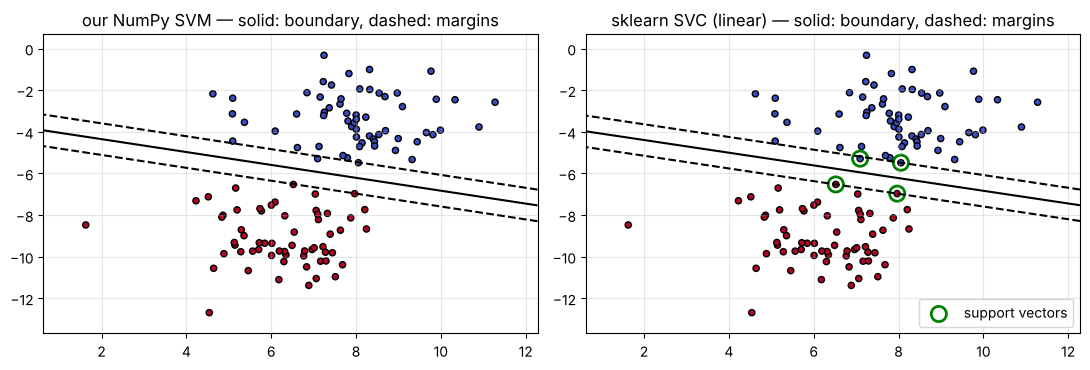

In [12]:
# 🔢 NumPy linear SVM (full-batch sub-gradient)
class LinearSVMNP:
    def __init__(self, lam=0.01, lr=0.1, epochs=20000):
        self.lam, self.lr, self.epochs = lam, lr, epochs
    def fit(self, X, y):
        n, d = X.shape; self.w, self.b = np.zeros(d), 0.0
        for _ in range(self.epochs):
            viol = y * (X @ self.w + self.b) < 1                         # mask of margin violators
            grad_w = self.lam * self.w - (y[viol, None] * X[viol]).sum(0) / n
            grad_b = -y[viol].sum() / n
            self.w -= self.lr * grad_w; self.b -= self.lr * grad_b
        return self
    def decision_function(self, X):
        return X @ self.w + self.b
    def predict(self, X):
        return np.sign(self.decision_function(X))

from sklearn.svm import SVC
svm_np = LinearSVMNP().fit(Xs, ys)
# Same objective in sklearn's units: C = 1 / (n · λ)
svm_sk = SVC(kernel="linear", C=1 / (len(ys) * 0.01)).fit(Xs, ys)
print("our w, b:    ", svm_np.w.round(3), round(svm_np.b, 3))
print("sklearn w, b:", svm_sk.coef_[0].round(3), round(svm_sk.intercept_[0], 3), " ← same street ✔")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, f) in zip(axes, [("our NumPy SVM", svm_np.decision_function), ("sklearn SVC (linear)", svm_sk.decision_function)]):
    x0, x1 = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 200), np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 200))
    Z = f(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape)
    ax.contour(x0, x1, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap="coolwarm", edgecolor="k", s=20); ax.set_title(name + " — solid: boundary, dashed: margins")
axes[1].scatter(*svm_sk.support_vectors_.T, s=120, facecolors="none", edgecolors="g", lw=2, label="support vectors")
axes[1].legend(loc="lower right"); plt.tight_layout(); plt.show()

## C3. The kernel trick — curved boundaries for free

When data isn't linearly separable, map it to a higher-dimensional space where it is. E.g. points inside vs outside a circle become separable if you add the feature $x_1^2 + x_2^2$ (the boundary becomes a flat plane "above" the circle).

The SVM's maths only ever uses **dot products** between points, $\mathbf{x}_i \cdot \mathbf{x}_j$. A **kernel** $K(\mathbf{x}_i, \mathbf{x}_j)$ computes the dot product in the high-dimensional space *without ever building it*. Popular kernels:
- **Linear:** $\mathbf{x}\cdot\mathbf{z}$
- **Polynomial:** $(\mathbf{x}\cdot\mathbf{z} + c)^p$
- **RBF / Gaussian:** $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ — a similarity score that's 1 for identical points and fades with distance. Corresponds to an *infinite*-dimensional space!

In [13]:
from sklearn.datasets import make_circles
Xc, yc = make_circles(300, factor=0.4, noise=0.1, random_state=0)

# Manual feature map: add r² = x1² + x2² and a LINEAR SVM can separate the rings
Xc3 = np.column_stack([Xc, (Xc ** 2).sum(1)])
print("linear SVM on raw 2-D:          ", SVC(kernel="linear").fit(Xc, yc).score(Xc, yc))
print("linear SVM on [x1, x2, x1²+x2²]:", SVC(kernel="linear").fit(Xc3, yc).score(Xc3, yc))
print("RBF-kernel SVM on raw 2-D:      ", SVC(kernel="rbf").fit(Xc, yc).score(Xc, yc), " ← kernel does it automatically")

linear SVM on raw 2-D:           0.5733333333333334
linear SVM on [x1, x2, x1²+x2²]: 1.0
RBF-kernel SVM on raw 2-D:       0.9966666666666667  ← kernel does it automatically


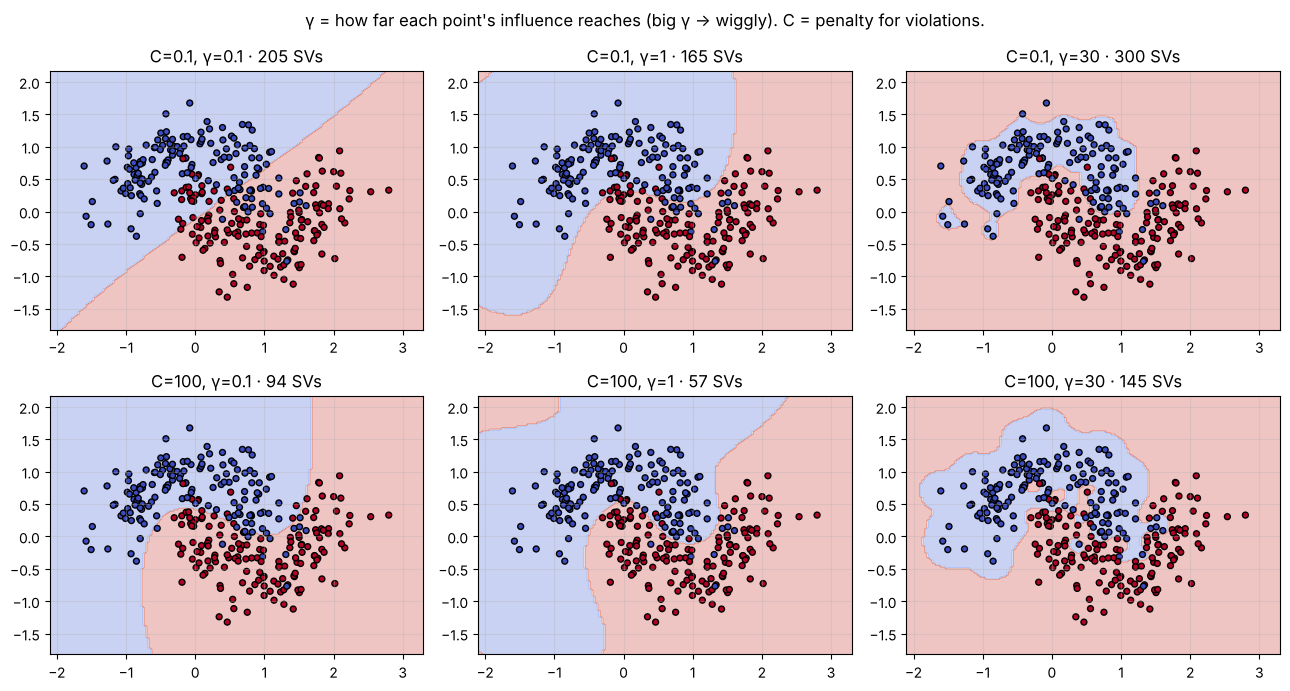

In [14]:
# Effect of C and gamma for the RBF kernel
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, C in enumerate([0.1, 100]):
    for j, gamma in enumerate([0.1, 1, 30]):
        m = SVC(kernel="rbf", C=C, gamma=gamma).fit(Xm, ym)
        plot_boundary(m.predict, Xm, ym, axes[i, j], f"C={C}, γ={gamma} · {len(m.support_)} SVs", h=150)
plt.suptitle("γ = how far each point's influence reaches (big γ → wiggly). C = penalty for violations.")
plt.tight_layout(); plt.show()

**SVM summary** — ✅ strong on small/medium data with many features, kernel trick gives flexible boundaries, only support vectors matter. ❌ slow beyond ~100k samples (kernel version), needs scaling, sensitive to C/γ (tune with CV), doesn't give probabilities natively.

---
## Head-to-head on real data

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
Xb, yb = load_breast_cancer(return_X_y=True)
candidates = {
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "Gaussian NB": GaussianNB(),
    "Linear SVM": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "RBF SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression()),
}
for name, model in candidates.items():
    s = cross_val_score(model, Xb, yb, cv=5)
    print(f"{name:20s} accuracy {s.mean():.3f} ± {s.std():.3f}")

KNN (k=5)            accuracy 0.965 ± 0.010
Gaussian NB          accuracy 0.939 ± 0.015
Linear SVM           accuracy 0.972 ± 0.009
RBF SVM              accuracy 0.974 ± 0.015
Logistic regression  accuracy 0.981 ± 0.007


## Key takeaways
- **KNN:** vote of the k nearest points; choose k by CV; always scale; struggles in high dimensions.
- **Naive Bayes:** Bayes' rule + "features independent given class"; work in log space; Laplace smoothing for unseen words.
- **SVM:** maximum-margin boundary defined by support vectors; hinge loss; kernels give non-linear boundaries; tune C and γ.

## Exercises
1. Add **distance-weighted voting** to `KNNClassifierNP` (closer neighbours get weight 1/distance). Compare with sklearn's `weights="distance"`.
2. Set `alpha=0` in `mnb_fit_python` and classify `"free lunch"`. What goes wrong?
3. Write an RBF kernel function in NumPy and check it matches `sklearn.metrics.pairwise.rbf_kernel`.

In [16]:
# Exercise 3 — solution
from sklearn.metrics.pairwise import rbf_kernel
def rbf_kernel_np(A, B, gamma=1.0):
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * d2)
A, B = rng.normal(size=(4, 3)), rng.normal(size=(5, 3))
print("matches sklearn:", np.allclose(rbf_kernel_np(A, B, 0.5), rbf_kernel(A, B, gamma=0.5)))

matches sklearn: True


In [17]:
# Exercise 2 — solution: log(0) is undefined → the model crashes (or with numpy, gives -inf and vetoes the class)
try:
    mnb_fit_python(train_docs, alpha=0.0)
except ValueError as e:
    print("ValueError:", e, "→ a word unseen in one class gets probability 0, log(0) = −∞. That's why we smooth.")

ValueError: math domain error → a word unseen in one class gets probability 0, log(0) = −∞. That's why we smooth.


**Next:** [05 · Decision Trees & Ensembles](05_decision_trees_and_ensembles.ipynb) — the models that win most tabular-data competitions.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §3.4–3.6 · `Probability_Statistics_Notes.md` §1.2 (Bayes & base rates) · `Calculus_Notes.md` Part 9 (Lagrange/KKT — the SVM dual) · code: `ml_from_scratch.py` → `KNNClassifier`, `GaussianNaiveBayes`, `MultinomialNaiveBayes`, `LinearSVM`, `KernelSVM` (SMO).